## Ejercicio 9

Trabajo Práctico — Reconstrucción y regularización en imágenes tomográficas

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

In [2]:
X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = X_fantoma.shape[0]
x_fantoma = X_fantoma.reshape(-1)

In [3]:
def mascara_rayo(n, direccion, s):
    alfa = direccion[0]
    beta = direccion[1]
    matriz = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(n):
            if alfa * i + beta * j == s:
                matriz[i][j] = 1
    return matriz


def matriz_proyeccion(n, direcciones):
    filas_A = []
    rayos = []

    for direccion in direcciones:
        alfa = direccion[0]
        beta = direccion[1]
        valores_s = set()

        for i in range(n):
            for j in range(n):
                valores_s.add(alfa * i + beta * j)

        for s in sorted(valores_s):
            mascara = mascara_rayo(n, direccion, s)
            filas_A.append(mascara.reshape(-1))
            rayos.append((direccion, s))

    A = np.array(filas_A, dtype=float)
    return A, rayos

In [4]:
D2 = [(1, 0), (0, 1)]
D4 = D2 + [(1, 1), (1, -1)]
D7 = D4 + [(2, 1), (1, 2), (3, 1)]

A2, rayos2 = matriz_proyeccion(n, D2)
A4, rayos4 = matriz_proyeccion(n, D4)
A7, rayos7 = matriz_proyeccion(n, D7)

### Inciso a)

In [5]:
def matriz_diferencias(n):
    filas_h = []
    filas_v = []

    for i in range(n):
        for j in range(n - 1):
            k = i * n + j
            fila = np.zeros(n**2)
            fila[k] = -1
            fila[k + 1] = 1
            filas_h.append(fila)

    for i in range(n - 1):
        for j in range(n):
            k = i * n + j
            fila = np.zeros(n**2)
            fila[k] = -1
            fila[k + n] = 1
            filas_v.append(fila)

    return np.array(filas_h + filas_v, dtype=float)

In [6]:
D = matriz_diferencias(n)
print("Dimensiones de D:", D.shape)
print("¿Cada fila tiene un -1?", np.all(np.sum(D == -1, axis=1) == 1))
print("¿Cada fila tiene un 1?", np.all(np.sum(D == 1, axis=1) == 1))
assert D.shape == (112, 64)
assert np.all(np.sum(D == -1, axis=1) == 1)
assert np.all(np.sum(D == 1, axis=1) == 1)
assert np.all(np.count_nonzero(D, axis=1) == 2)

Dx = D @ x_fantoma
assert np.allclose(Dx[:n*(n-1)], np.diff(X_fantoma, axis=1).reshape(-1))
assert np.allclose(Dx[n*(n-1):], np.diff(X_fantoma, axis=0).reshape(-1))

Dimensiones de D: (112, 64)
¿Cada fila tiene un -1? True
¿Cada fila tiene un 1? True


### Inciso b)

In [7]:
x_constante = np.ones(n**2)
print("Norma de D @ x_constante:", np.linalg.norm(D @ x_constante))
print("Norma de D @ x_fantoma:", np.linalg.norm(D @ x_fantoma))
assert np.allclose(D @ x_constante, 0)

Norma de D @ x_constante: 0.0
Norma de D @ x_fantoma: 2.7055498516937364


En una imagen constante, todos los vecinos tienen el mismo valor. Cada fila de `D` resta
dos valores iguales, por eso todas las diferencias son cero. El fantoma tiene bordes y
cambios de atenuación: su norma de diferencias es aproximadamente 2,706.

### Inciso c)

El costo es

$$J_{\sigma,\lambda}(x)=\frac12\|A_7x-b_\sigma\|^2+
\frac\lambda2\|Dx\|^2.$$

El primer término mide la fidelidad a las mediciones. El segundo penaliza los cambios
entre píxeles vecinos. En particular,

$$\|Dx\|^2=\sum_{i=0}^{n-1}\sum_{j=0}^{n-2}(X_{i,j+1}-X_{ij})^2+
\sum_{i=0}^{n-2}\sum_{j=0}^{n-1}(X_{i+1,j}-X_{ij})^2.$$

La norma $\|Dx\|$ mide la variación total en sentido cuadrático, no la amplitud absoluta
de la imagen: sumar una constante no cambia sus diferencias. Con $\lambda=0$ obtenemos
mínimos cuadrados. Al aumentar $\lambda$, damos más importancia a la suavidad, lo que
puede reducir ruido y también borrar bordes reales.

### Inciso d)

In [8]:
b7 = A7 @ x_fantoma
rng = np.random.default_rng(2026)
z = rng.standard_normal(b7.size)
escala = np.sqrt(np.mean(b7**2))

In [9]:
sigmas = [0.0, 0.10, 0.20]
lambdas = [0.0, 0.1, 0.3, 1.0]
mediciones = {sigma: b7 + sigma * escala * z for sigma in sigmas}
print("Usamos la misma semilla 2026 y el mismo vector z del ejercicio 6.")

Usamos la misma semilla 2026 y el mismo vector z del ejercicio 6.


### Inciso e)

In [10]:
def gradiente_descendiente(A, b, alpha, max_iter=10000, tol=1e-8,
                          D=None, lam=0.0, x_ref=None):
    x = np.zeros(A.shape[1], dtype=float)
    AT = A.T
    DT = None if D is None else D.T
    costos = []
    normas_gradiente = []
    errores = []
    norma_inicial = None
    motivo = "máximo de iteraciones"

    t = 0
    for t in range(max_iter + 1):
        residuo = A @ x - b
        costo = 0.5 * np.dot(residuo, residuo)
        grad = AT @ residuo

        if D is not None and lam != 0:
            diferencias = D @ x
            costo += 0.5 * lam * np.dot(diferencias, diferencias)
            grad = grad + lam * (DT @ diferencias)

        norma_grad = np.linalg.norm(grad)
        if norma_inicial is None:
            norma_inicial = norma_grad

        costos.append(float(costo))
        normas_gradiente.append(float(norma_grad))
        # La referencia se usa solamente para registrar el error, nunca para detenernos.
        if x_ref is not None:
            errores.append(np.linalg.norm(x - x_ref) / np.linalg.norm(x_ref))

        if not np.isfinite(costo) or costo > 1e25:
            motivo = "costo divergente"
            break
        if norma_grad <= tol * max(1.0, norma_inicial):
            motivo = "tolerancia del gradiente"
            break
        if t == max_iter:
            break

        x = x - alpha * grad

    return {"x": x, "costos": np.array(costos),
            "normas_gradiente": np.array(normas_gradiente),
            "errores": np.array(errores), "iteraciones": t, "motivo": motivo}

Reutilizamos la actualización de gradiente y agregamos $\lambda D^TDx$ al gradiente.
La función siempre comienza con $x_0=0$. El argumento `x_ref` permite registrar el error
del fantoma para los gráficos, pero no participa de la actualización ni de la parada.

### Inciso f)

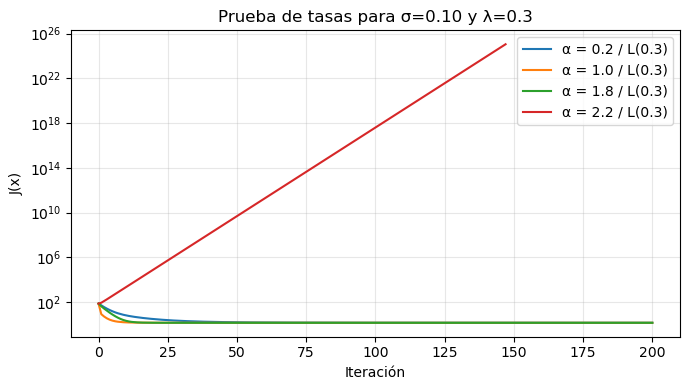

Tasa común elegida: 0.04934652837164658
Límite más restrictivo: 0.0548294759684962
Tolerancia relativa del gradiente: 1e-9; máximo: 10000 iteraciones.
σ=0.00, λ=0.0: 522 iteraciones, tolerancia del gradiente
σ=0.00, λ=0.1: 335 iteraciones, tolerancia del gradiente
σ=0.00, λ=0.3: 199 iteraciones, tolerancia del gradiente
σ=0.00, λ=1.0: 94 iteraciones, tolerancia del gradiente
σ=0.10, λ=0.0: 556 iteraciones, tolerancia del gradiente
σ=0.10, λ=0.1: 355 iteraciones, tolerancia del gradiente
σ=0.10, λ=0.3: 209 iteraciones, tolerancia del gradiente
σ=0.10, λ=1.0: 95 iteraciones, tolerancia del gradiente
σ=0.20, λ=0.0: 574 iteraciones, tolerancia del gradiente
σ=0.20, λ=0.1: 365 iteraciones, tolerancia del gradiente
σ=0.20, λ=0.3: 215 iteraciones, tolerancia del gradiente
σ=0.20, λ=1.0: 96 iteraciones, tolerancia del gradiente


In [11]:
H = A7.T @ A7
DtD = D.T @ D
L_por_lambda = {lam: np.linalg.eigvalsh(H + lam * DtD)[-1] for lam in lambdas}
L_max = max(L_por_lambda.values())

# Probamos tasas con el caso sigma=0.10 y lambda=0.3.
fig, ax = plt.subplots(figsize=(7, 4))
for factor in [0.2, 1.0, 1.8, 2.2]:
    tasa = factor / L_por_lambda[0.3]
    prueba = gradiente_descendiente(A7, mediciones[0.1], tasa,
                                    max_iter=200, tol=1e-9, D=D, lam=0.3)
    ax.semilogy(prueba["costos"], label=f"α = {factor:.1f} / L(0.3)")
ax.set_xlabel("Iteración")
ax.set_ylabel("J(x)")
ax.set_title("Prueba de tasas para σ=0.10 y λ=0.3")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Esta tasa es estable para todos los valores de lambda considerados.
alpha = 1.8 / L_max
print("Tasa común elegida:", alpha)
print("Límite más restrictivo:", 2.0 / L_max)
print("Tolerancia relativa del gradiente: 1e-9; máximo: 10000 iteraciones.")

resultados = {}
for sigma in sigmas:
    for lam in lambdas:
        resultado = gradiente_descendiente(
            A7, mediciones[sigma], alpha, max_iter=10000, tol=1e-9,
            D=D, lam=lam, x_ref=x_fantoma
        )
        resultados[sigma, lam] = resultado
        print(f"σ={sigma:.2f}, λ={lam:.1f}: {resultado['iteraciones']} iteraciones, "
              f"{resultado['motivo']}")
        assert resultado["motivo"] == "tolerancia del gradiente"
        assert np.all(np.diff(resultado["costos"]) <= 1e-9)
        # Comprobación independiente del resultado; no interviene en la parada.
        referencia = np.linalg.solve(H + lam * DtD, A7.T @ mediciones[sigma])
        assert np.allclose(resultado["x"], referencia, atol=1e-6)

La Hessiana es $A_7^TA_7+\lambda D^TD$. Calculamos su mayor autovalor para elegir una
tasa menor que $2/L(\lambda)$ en todos los casos. La prueba con $2{,}2/L(0{,}3)$ muestra
la inestabilidad fuera del intervalo.

La parada exige $\|\nabla J(x_t)\|\leq10^{-9}\max(1,\|\nabla J(x_0)\|)$ o alcanzar
el máximo de iteraciones. No usamos el error respecto del fantoma para decidir cuándo parar.

### Inciso g)

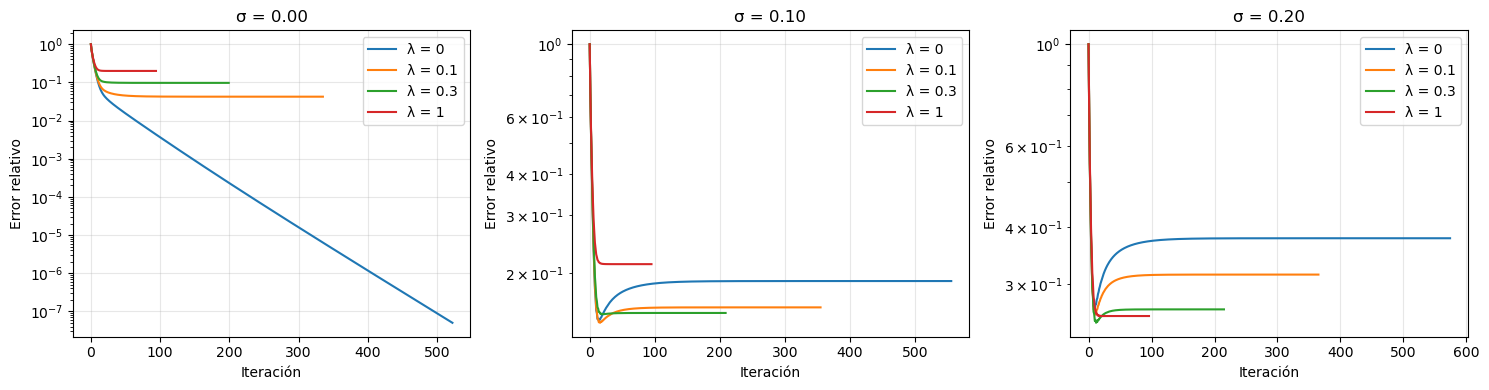

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, sigma in zip(axs, sigmas):
    for lam in lambdas:
        ax.semilogy(resultados[sigma, lam]["errores"], label=f"λ = {lam:g}")
    ax.set_title(f"σ = {sigma:.2f}")
    ax.set_xlabel("Iteración")
    ax.set_ylabel("Error relativo")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Inciso h)

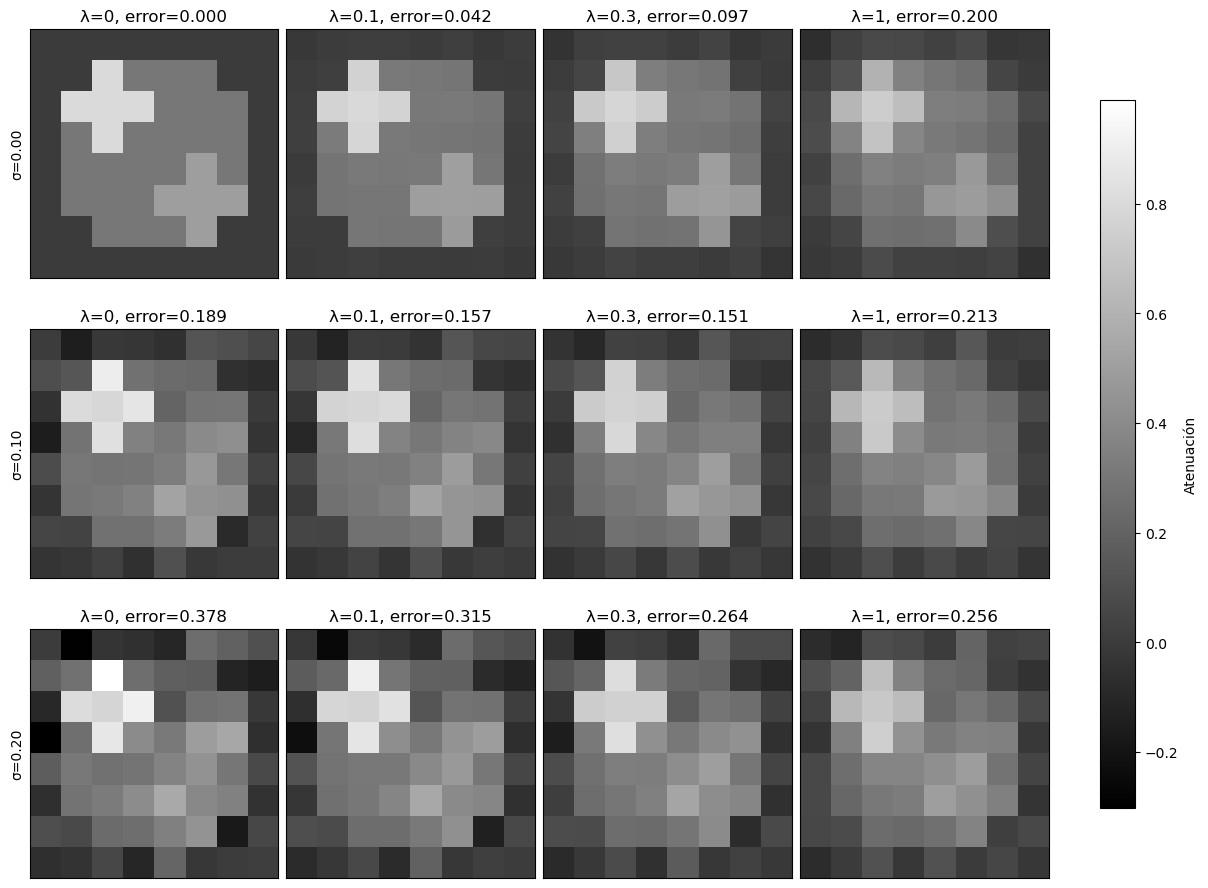

In [13]:
vmin = min(0.0, min(r["x"].min() for r in resultados.values()))
vmax = max(X_fantoma.max(), max(r["x"].max() for r in resultados.values()))
fig, axs = plt.subplots(len(sigmas), len(lambdas), figsize=(12, 9), layout="constrained")
for i, sigma in enumerate(sigmas):
    for j, lam in enumerate(lambdas):
        resultado = resultados[sigma, lam]
        im = axs[i, j].imshow(resultado["x"].reshape(n, n), cmap="gray", vmin=vmin, vmax=vmax)
        axs[i, j].set_title(f"λ={lam:g}, error={resultado['errores'][-1]:.3f}")
        axs[i, j].set_xticks([])
        axs[i, j].set_yticks([])
        if j == 0:
            axs[i, j].set_ylabel(f"σ={sigma:.2f}")
fig.colorbar(axs[0, 0].images[0], ax=axs, label="Atenuación", shrink=0.8)
plt.show()

### Inciso i)

σ=0.00: mejor λ=0, error=0.000000
σ=0.10: mejor λ=0.3, error=0.150892
σ=0.20: mejor λ=1, error=0.255698


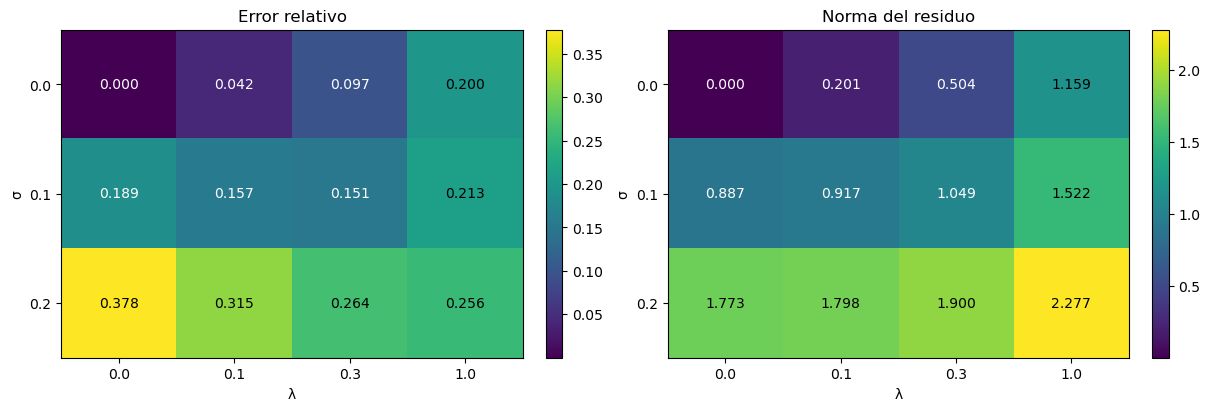

In [14]:
errores_finales = np.zeros((len(sigmas), len(lambdas)))
residuos_finales = np.zeros_like(errores_finales)
mejores = {}
for i, sigma in enumerate(sigmas):
    for j, lam in enumerate(lambdas):
        x = resultados[sigma, lam]["x"]
        errores_finales[i, j] = np.linalg.norm(x - x_fantoma) / np.linalg.norm(x_fantoma)
        residuos_finales[i, j] = np.linalg.norm(A7 @ x - mediciones[sigma])
    indice = np.argmin(errores_finales[i])
    mejores[sigma] = lambdas[indice]
    print(f"σ={sigma:.2f}: mejor λ={lambdas[indice]:g}, error={errores_finales[i, indice]:.6f}")

fig, axs = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, tabla, titulo in zip(axs, [errores_finales, residuos_finales],
                             ["Error relativo", "Norma del residuo"]):
    im = ax.imshow(tabla, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(lambdas)), [str(lam) for lam in lambdas])
    ax.set_yticks(range(len(sigmas)), [str(sigma) for sigma in sigmas])
    ax.set_xlabel("λ")
    ax.set_ylabel("σ")
    ax.set_title(titulo)
    for i in range(len(sigmas)):
        for j in range(len(lambdas)):
            color = "white" if tabla[i, j] < (tabla.max() + tabla.min()) / 2 else "black"
            ax.text(j, i, f"{tabla[i, j]:.3f}", ha="center", va="center", color=color)
    fig.colorbar(im, ax=ax)
plt.show()

### Inciso j)

Sin ruido, el mejor valor es $\lambda=0$: `A7` ya determina el fantoma y la regularización
agrega un sesgo de suavizado. Con $\lambda=1$ el error sin ruido sube aproximadamente a $0{,}200$.

Para $\sigma=0{,}10$, el mejor valor de los probados es $\lambda=0{,}3$: el error baja
de $0{,}189$ sin regularización a $0{,}151$. Con $\lambda=1$ vuelve a subir a $0{,}213$,
porque el suavizado borra detalles útiles.

Para $\sigma=0{,}20$, el mejor de los valores probados es $\lambda=1$, y el error baja
de $0{,}378$ a $0{,}256$. En esta experiencia conviene penalizar más cuando aumenta el ruido.
Eso no demuestra que el mejor valor posible sea exactamente uno: solamente es el mejor
de la grilla considerada.

La regularización permite aceptar un residuo mayor para obtener una imagen más cercana al
fantoma. Si la penalización es excesiva, los píxeles vecinos se igualan demasiado y se pierden
bordes y regiones pequeñas. Las curvas del error también muestran que un buen ajuste de
mediciones y una buena reconstrucción no siempre mejoran juntos.

Asistencia utilizada: ChatGPT / Codex para completar y revisar el código, las explicaciones y las verificaciones de este notebook.